# Initialization

In [ ]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt
import seaborn as sns
import numpy as np


from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')


#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out




# Data Load-In

In [2]:

season_map = {

    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Fall',
    10: 'Fall',
    11: 'Fall',
}


datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"

fulldat = pd.read_csv(datapath+"fulldat-unaggregated-pixelmask.csv")
fulldat['datetime'] = pd.to_datetime(fulldat['datetime'], errors='coerce')
fulldat['hour'] = fulldat['datetime'].dt.hour
fulldat['season'] = fulldat['month'].map(season_map)

hourly = pd.read_csv(datapath+"fulldat-hourly-timeseries.csv")
hourly['datetime'] = pd.to_datetime(hourly['datetime'], errors='coerce')
hourly['hour'] = hourly['datetime'].dt.hour

diurnal = pd.read_csv(datapath+"fulldat-diurnal-aggregation.csv")
weekly = pd.read_csv(datapath+"fulldat-weekly-aggregation.csv")
monthly_diurnal = pd.read_csv(datapath+"fulldat-monthly-diurnal-aggregation.csv")
seasonal_diurnal = pd.read_csv(datapath+"fulldat-seasonal-diurnal-aggregation.csv")
monthly = pd.read_csv(datapath+"fulldat-monthly-aggregation.csv")



In [25]:
hourly

,Unnamed: 0,datetime,latitude,longitude,col_no2_mean,col_no2_median,col_no2_var,col_no2_sd,sfc_no2_mean,sfc_no2_median,...,solar_zenith_median,windspeed_2m_mean,windspeed_2m_median,winddir_2m_mean,winddir_2m_median,windspeed_10m_mean,windspeed_10m_median,winddir_10m_mean,winddir_10m_median,hour
0,0,2025-09-01,41.65,-87.61,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,1,2025-09-01,41.65,-87.57,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2,2025-09-01,41.65,-87.55,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,3,2025-09-01,41.65,-87.53,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,4,2025-09-01,41.67,-87.67,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9926100,9926100,2026-06-15,42.01,-87.81,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9926101,9926101,2026-06-15,42.01,-87.79,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9926102,9926102,2026-06-15,42.01,-87.77,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9926103,9926103,2026-06-15,42.01,-87.71,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


# MLR Over Hourly Timeseries Data 


In [12]:
var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean', 'u10m_mean', 'v10m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean', 'u10m_mean', 'v10m_mean']

model_frame = hourly[var_select].dropna().copy()

train_df, test_df = train_test_split(model_frame, test_size=0.2, random_state=1219)

scaler_x = StandardScaler().fit(train_df[feature_cols])
scaler_y = StandardScaler().fit(train_df[[target_col]])

x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)


print(f"Train rows: {len(train_df)}, Test rows: {len(test_df)}")

model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

train_score = r2_score(y_train, model.predict(x_train))
test_score = r2_score(y_test, model.predict(x_test))

print(f"\nTrain R2: {train_score:.3f}")
print(f"Test R2: {test_score:.3f}")

coef = np.ravel(model.coef_)
intercept = float(model.intercept_)

print("Coef: ", coef)
print("Intercept: ", intercept)


def estimate_no2(col_no2, pbl, sza, u2m, v2m, u10m, v10m):
    return (intercept + coef[0] * col_no2 + coef[1] * pbl + coef[2] * sza 
            + coef[3] * u2m + coef[4] * v2m + coef[5]*u10m + coef[6]*v10m)

x_train_est = x_train.copy()
x_train_est['no2_estimate'] = x_train_est.apply(
    lambda row: estimate_no2(
        row.col_no2_mean,
        row.pbl_mean,
        row.solar_zenith_mean,
        row.u2m_mean,
        row.v2m_mean,
        row.u10m_mean,
        row.v10m_mean,
    ),
    axis=1,
)

# Convert the scaled prediction back to the original NO2 units.
x_train_est['no2_estimate_unscaled'] = scaler_y.inverse_transform(x_train_est[['no2_estimate']]).ravel()


x_test_est = x_test.copy()
x_test_est['no2_estimate'] = x_test_est.apply(
    lambda row: estimate_no2(
        row.col_no2_mean,
        row.pbl_mean,
        row.solar_zenith_mean,
        row.u2m_mean,
        row.v2m_mean,
        row.u10m_mean,
        row.v10m_mean,
    ),
    axis=1,
)

# Convert the scaled prediction back to the original NO2 units.
x_test_est['no2_estimate_unscaled'] = scaler_y.inverse_transform(x_test_est[['no2_estimate']]).ravel()



Train rows: 114492, Test rows: 28624

Train R2: 0.273
Test R2: 0.277
Coef:  [ 0.21510197 -0.33144956  0.18096927 -0.60950135 -0.56506823  0.69826415
  0.73805688]
Intercept:  -6.019022427151503e-17


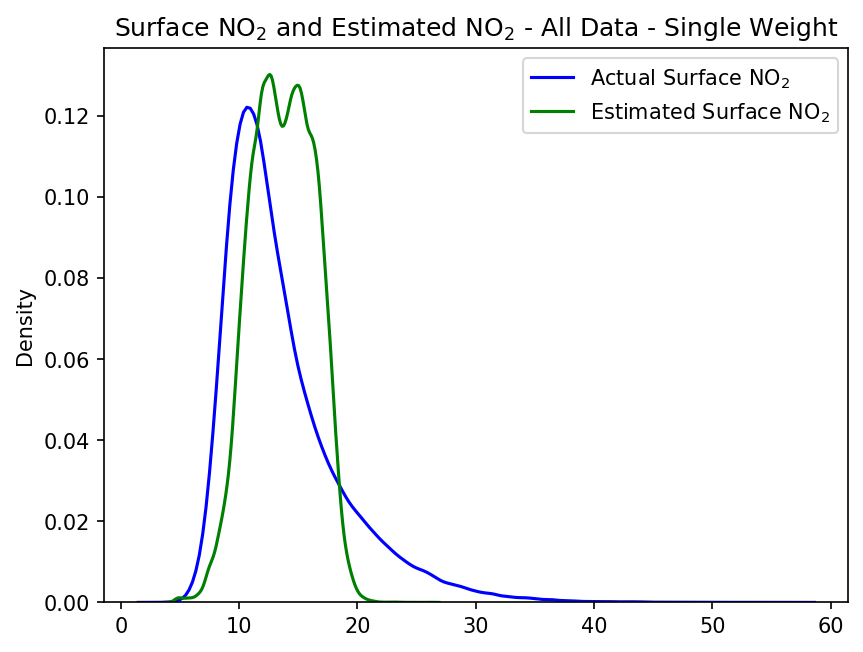

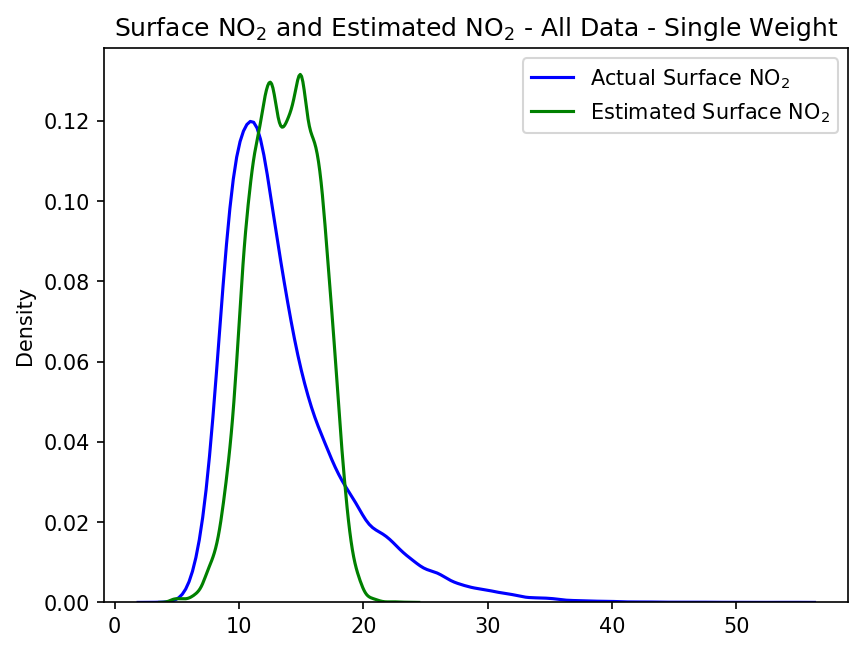

In [13]:
actual_surface = train_df['sfc_no2_mean'].to_numpy()
estimated_surface = x_train_est['no2_estimate_unscaled'].to_numpy()
actual_surface_test = test_df['sfc_no2_mean'].to_numpy()
estimated_surface_test = x_test_est['no2_estimate_unscaled'].to_numpy()


sns.kdeplot(actual_surface, color='blue', label='Actual Surface NO$_2$')
sns.kdeplot(estimated_surface, color='green', label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
# savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

sns.kdeplot(actual_surface_test, color='blue', label='Actual Surface NO$_2$')
sns.kdeplot(estimated_surface_test, color='green', label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
# savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

# eqn_text = f"y = 

In [14]:
var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean', 'u10m_mean','v10m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean', 'u10m_mean','v10m_mean']
meta_cols = ['datetime', 'latitude', 'longitude']

def estimate_no2_from_model(x):
    return (
        intercept
        + coef[0] * x['col_no2_mean']
        + coef[1] * x['pbl_mean']
        + coef[2] * x['solar_zenith_mean']
        + coef[3] * x['u2m_mean']
        + coef[4] * x['v2m_mean']
        + coef[5] * x['u10m_mean']
        + coef[6] * x['v10m_mean']
    )

month_results = []
monthly_estimates = []

for month in sorted(hourly['datetime'].dt.month.dropna().unique()):
    month_frame = hourly.loc[
        hourly['datetime'].dt.month == month,
        meta_cols + var_select
    ].dropna().copy()
    if len(month_frame) < 10:
        continue

    train_df, test_df = train_test_split(month_frame, test_size=0.2, random_state=1219)

    scaler_x = StandardScaler().fit(train_df[feature_cols])
    scaler_y = StandardScaler().fit(train_df[[target_col]])

    x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
    x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

    y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
    y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)

    model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

    intercept = float(model.intercept_)
    coef = np.ravel(model.coef_)

    train_est_scaled = x_train.apply(estimate_no2_from_model, axis=1)
    test_est_scaled = x_test.apply(estimate_no2_from_model, axis=1)

    train_estimates = scaler_y.inverse_transform(pd.DataFrame(train_est_scaled, columns=['no2_estimate'])).ravel()
    test_estimates = scaler_y.inverse_transform(pd.DataFrame(test_est_scaled, columns=['no2_estimate'])).ravel()

    train_est = train_df[meta_cols + ['sfc_no2_mean']].copy()
    train_est['no2_estimate'] = train_estimates
    train_est['month'] = month
    train_est['split'] = 'train'
    train_est['residual'] = train_est['sfc_no2_mean'] - train_est['no2_estimate']

    test_est = test_df[meta_cols + ['sfc_no2_mean']].copy()
    test_est['no2_estimate'] = test_estimates
    test_est['month'] = month
    test_est['split'] = 'test'
    test_est['residual'] = test_est['sfc_no2_mean'] - test_est['no2_estimate']

    monthly_estimates.append(pd.concat([train_est, test_est], axis=0))

    month_results.append({
        'month': month,
        'train_rows': len(train_df),
        'test_rows': len(test_df),
        'train_score': r2_score(y_train, model.predict(x_train)),
        'test_score': r2_score(y_test, model.predict(x_test)),
        'intercept': intercept,
        'coef_col_no2': float(coef[0]),
        'coef_pbl': float(coef[1]),
        'coef_sza': float(coef[2]),
        'coef_u2m': float(coef[3]),
        'coef_v2m': float(coef[4]),
        'coef_u10m': float(coef[5]),
        'coef_v10m': float(coef[6]),
    })

model_vals = pd.DataFrame(month_results)
print(model_vals)

monthly_estimates_df = pd.concat(monthly_estimates, axis=0, ignore_index=True)
print(monthly_estimates_df.head())
monthly_estimates_df

   month  train_rows  test_rows  train_score  test_score     intercept  \
0      1        3564        891     0.209038    0.213609  3.848688e-17   
1      2        8840       2211     0.396873    0.394033  1.777910e-17   
2      3       13362       3341     0.229664    0.257866  7.186541e-17   
3      4       11961       2991     0.384528    0.376982 -3.783600e-16   
4      5       19880       4971     0.312097    0.300507 -1.112857e-16   
5      6          61         16     0.473439    0.414553  6.827529e-12   
6      9       24684       6171     0.320084    0.297239  2.629998e-16   
7     10       18185       4547     0.279791    0.278330  2.694437e-17   
8     11       10958       2740     0.445674    0.416023  2.063652e-16   
9     12        2993        749     0.194150    0.177036 -8.058207e-16   

   coef_col_no2  coef_pbl   coef_sza     coef_u2m     coef_v2m    coef_u10m  \
0      0.017742 -0.448554   0.260890     0.145748     3.456535    -0.037926   
1      0.192428 -0.430320  

,datetime,latitude,longitude,sfc_no2_mean,no2_estimate,month,split,residual
0,2026-01-05 15:00:00,41.97,-87.65,19.197727,17.953377,1,train,1.244350
1,2026-01-13 18:00:00,41.71,-87.67,13.770000,12.502545,1,train,1.267455
2,2026-01-05 16:00:00,41.79,-87.61,16.016667,16.391384,1,train,-0.374717
3,2026-01-05 17:00:00,41.69,-87.63,10.853333,14.643646,1,train,-3.790313
4,2026-01-06 16:00:00,41.95,-87.79,23.310000,16.411187,1,train,6.898813
...,...,...,...,...,...,...,...,...
143111,2025-12-18 14:00:00,41.67,-87.63,12.374000,9.134442,12,test,3.239558
143112,2025-12-23 14:00:00,41.89,-87.77,20.877500,23.137534,12,test,-2.260034
143113,2025-12-17 14:00:00,41.87,-87.63,34.287500,19.630735,12,test,14.656765
143114,2025-12-23 15:00:00,41.77,-87.75,13.626667,21.558570,12,test,-7.931904


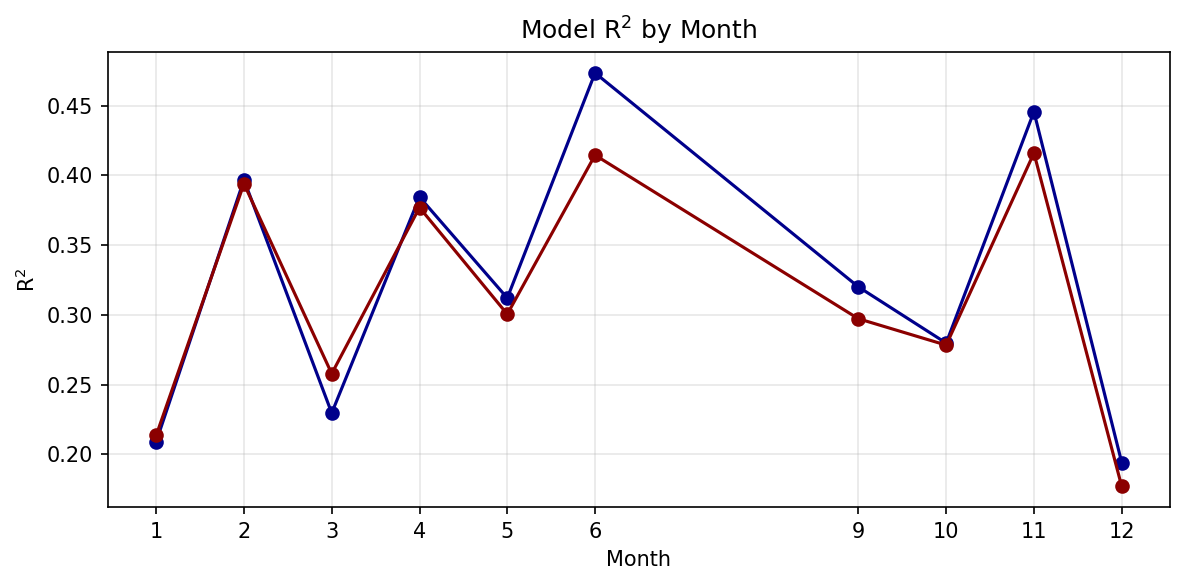

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(model_vals['month'], model_vals['train_score'], marker='o', color='darkblue')
plt.plot(model_vals['month'], model_vals['test_score'], marker='o', color='darkred')
plt.xticks(model_vals['month'])
plt.xlabel('Month')
plt.ylabel('R$^2$')
plt.title('Model R$^2$ by Month')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


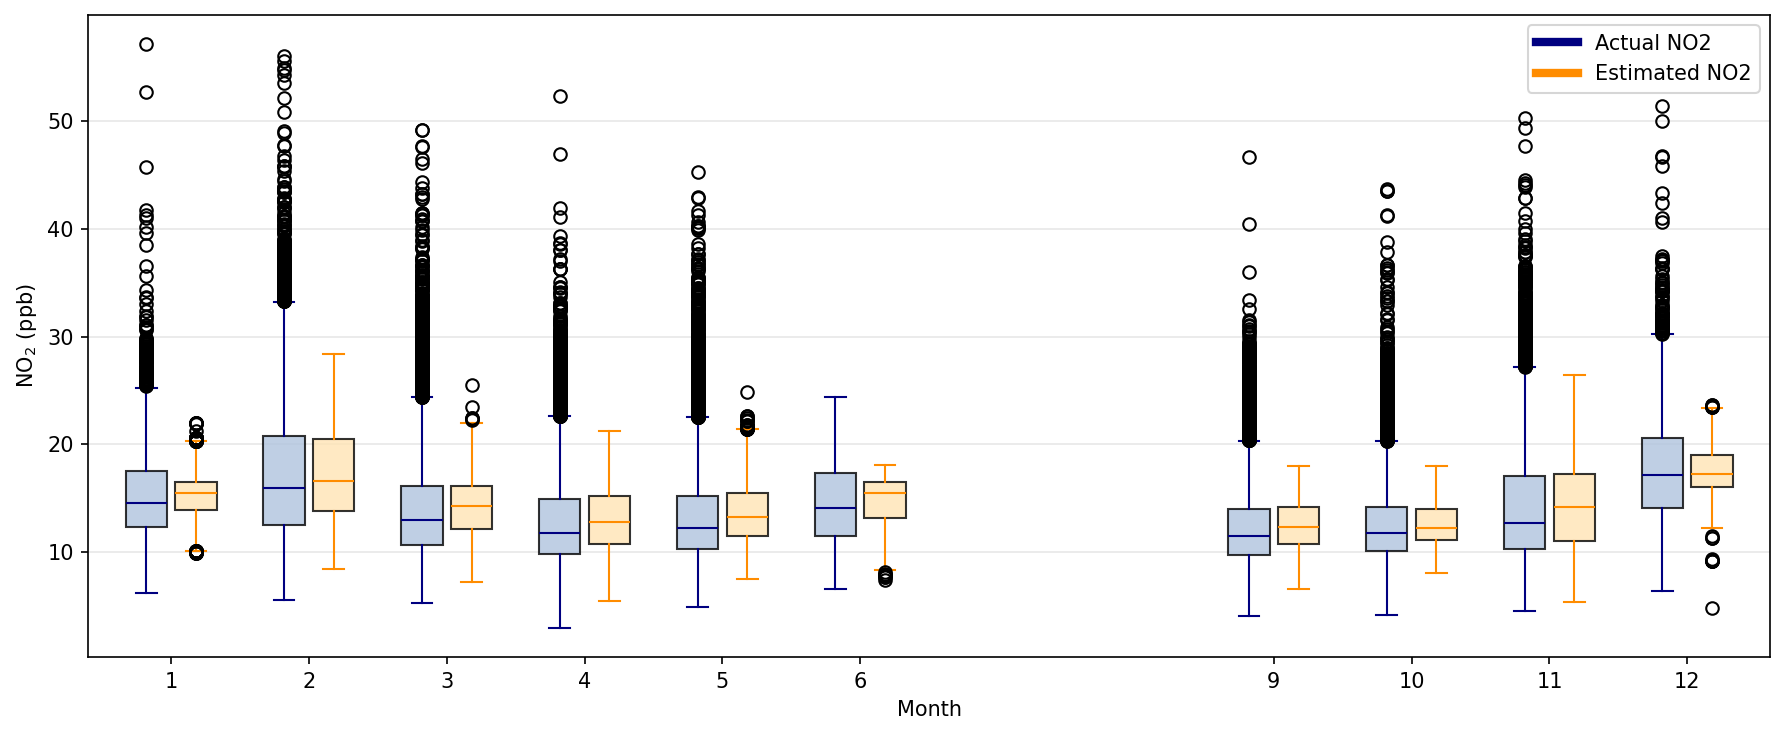

In [16]:
max_points_per_box = 10000

monthly_estimates_plot = (
    monthly_estimates_df[['month', 'sfc_no2_mean', 'no2_estimate']]
    .dropna(subset=['sfc_no2_mean', 'no2_estimate'])
    .copy()
)
monthly_estimates_plot['month'] = monthly_estimates_plot['month'].astype(int)

months = []
actual_by_hour = []
estimated_by_hour = []

rng = np.random.default_rng(41)

for month, group in monthly_estimates_plot.groupby('month', sort=True):
    months.append(int(month))

    actual_values = group['sfc_no2_mean'].to_numpy(dtype=float)
    estimated_values = group['no2_estimate'].to_numpy(dtype=float)

    if len(actual_values) > max_points_per_box:
        sample_idx = rng.choice(len(actual_values), size=max_points_per_box, replace=False)
        actual_values = actual_values[sample_idx]
        estimated_values = estimated_values[sample_idx]

    actual_by_hour.append(actual_values)
    estimated_by_hour.append(estimated_values)

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [month - 0.18 for month in months]
positions_estimated = [month + 0.18 for month in months]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(months)
ax.set_xticklabels(months)
ax.set_xlim(min(months) - 0.6, max(months) + 0.6)
ax.set_xlabel('Month')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()
plt.show()

# TESTING BELOW HERE

In [ ]:



months = chi_result_monthly['month_year'].unique()
months = months[months.argsort()]

start_date = chi_result_monthly['month_year'].min()
end_date = chi_result_monthly['month_year'].max()

delta = relativedelta(months=1)

fig, axes = plt.subplots(
    nrows=3, ncols=4,
    figsize=(20, 15)
)

for ax, month in zip(axes.flatten(), range(1,13)):
# while start_date <= end_date:
    # ax = axes[i]

    # Base Chicago boundary
    chicago.plot(color='white', edgecolor='black', ax=ax)
    
    # Filter to month
    monthly_data = chi_result_monthly[chi_result_monthly['month_year'] == start_date]
    
    if not monthly_data.empty:
        monthly_data.plot(ax=ax, column='avg_value', cmap='BuPu',
                          vmin=chi_result_monthly['avg_value'].min(),
                          vmax=chi_result_monthly['avg_value'].max())
    
    # ax.set_title(calendar.month_name[month])
    # ax.axis('off')
    title_date = dt.date(start_date.year, start_date.month, start_date.day).strftime('%B %Y')
    ax.set_title(title_date, fontsize=12)
    ax.axis('off')

    start_date += delta

# Shared colorbar
sm = plt.cm.ScalarMappable(
    cmap='BuPu',
    norm=plt.Normalize(
        vmin=chi_result_monthly['avg_value'].min(),
        vmax=chi_result_monthly['avg_value'].max()
    )
)
sm._A = []
fig.colorbar(sm, ax=axes, shrink=0.5, label='Average NO2')

plt.suptitle('Monthly Avg NO2 - Chicago', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("month_avg_community.png")
plt.show()